# Python机器学习基础教程 ch04：数据表示与特征工程

对应笔记 [ch04.md](../ch04.md)。本 notebook 是**分节跟随代码**：小节结构与笔记一致，完整讲解、原书插图与“坑与陷阱”请看笔记页面。

运行环境：`machinelearn`（Python 3.10 / scikit-learn 1.7 / pandas 2.3 / mglearn，mglearn 已打 boston 本地数据补丁）。原书 0.19 时代 API 的适配处在代码注释中以 **版本适配** 标出，与笔记中的“版本差异” admonition 一一对应。

In [1]:
# ===== 公共设置（notebook 版新增；原书在 Jupyter 全局环境中运行）=====
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mglearn

# 兜底：nbclient/nbconvert 实跑时 inline 后端的 flush_figures 钩子未注册，
# 图会留在内存不进输出——这里手动补一个“每个 cell 结束时把打开的图显示出来”
import IPython
_ip = IPython.get_ipython()
if _ip is not None:
    def _flush_figs():
        if plt.get_fignums():
            plt.show()
    _ip.events.register("post_execute", _flush_figs)

print("sklearn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

sklearn 1.7.0 | pandas 2.3.3 | numpy 2.2.6


**本章解决**：机器学习算法只吃数字，但现实数据不是——"职业"是字符串、"小时"是整数编码的类别、租车量是带周期的时间序列。这一章讲**特征工程（feature engineering）**：如何把数据变换成对特定模型"好用"的表示（one-hot 编码、分箱、交互特征、多项式特征、log 变换），以及如何从一堆特征里挑出真正有用的那部分（单变量统计、模型选择、RFE）。
前三章你学的是"算法怎么工作"，这一章是分水岭：用正确的方式表示数据，对监督模型性能的影响比调参数还要大。学完本章再看第 5 章的模型评估与调参，工具箱就齐了。

## 4.1 分类变量

作为例子，我们将使用**美国成年人收入的数据集 adult**，该数据集是从 1994 年的普查数据库中导出的。任务是预测一名工人的收入是高于 50 000 美元还是低于 50 000 美元——这是一个二分类任务（也可以预测具体收入，那样就变成了回归任务，但问题更难，而且理解 50K 这条分界线本身也很有趣）。数据集的特征包括工人的年龄、雇用方式（独立经营、私营企业员工、政府职员等）、教育水平、性别、每周工作时长、职业，等等。表 4-1 给出了该数据集中的前几个条目：

### 4.1.1 One-Hot编码（虚拟变量）

到目前为止，表示分类变量最常用的方法就是 **one-hot 编码（one-hot-encoding）**或 **N 取一编码（one-out-of-N encoding）**，也叫**虚拟变量（dummy variable）**。背后的思想：**将一个分类变量替换为一个或多个新特征，新特征取值为 0 和 1**。对于线性二分类（以及 scikit-learn 中其他所有模型）的公式而言，0 和 1 这两个值是有意义的，我们可以对每个类别引入一个新特征，从而表示任意数量的类别。

In [2]:
import os
# 版本适配：原书按相对路径读 data/adult.data；UCI 数据需自行下载（https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data），
# 本机放在 E:\Desktop\深度学习\_ml_data\adult
ADULT_DIR = os.environ.get("ADULT_DIR", r"E:\Desktop\深度学习\_ml_data\adult")
# ===== 书 4.1.1 节：用 pandas 加载 adult 数据集 =====
import pandas as pd
from IPython.display import display

# 文件中没有包含列名称的表头，因此我们传入 header=None
# 然后在 "names" 中显式地提供列名称
data = pd.read_csv(
    os.path.join(ADULT_DIR, "adult.data"), header=None, index_col=False,
    names=['age', 'workclass', 'fnlwgt', 'education', 'education-num',
           'marital-status', 'occupation', 'relationship', 'race', 'gender',
           'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
           'income'])
# 为了便于说明，我们只选了其中几列
data = data[['age', 'workclass', 'education', 'gender', 'hours-per-week',
             'occupation', 'income']]
# IPython.display 可以在 Jupyter notebook 中输出漂亮的格式
display(data.head())

,age,workclass,education,gender,hours-per-week,occupation,income
0,39,State-gov,Bachelors,Male,40,Adm-clerical,<=50K
1,50,Self-emp-not-inc,Bachelors,Male,13,Exec-managerial,<=50K
2,38,Private,HS-grad,Male,40,Handlers-cleaners,<=50K
3,53,Private,11th,Male,40,Handlers-cleaners,<=50K
4,28,Private,Bachelors,Female,40,Prof-specialty,<=50K


In [3]:
# ===== 书 4.1.1 节：检查 gender 列的取值 =====
print(data.gender.value_counts())

gender
Male      21790
Female    10771
Name: count, dtype: int64


In [4]:
# ===== 书 4.1.1 节：get_dummies 一键编码 =====
print("Original features:\n", list(data.columns), "\n")
data_dummies = pd.get_dummies(data)
print("Features after get_dummies:\n", list(data_dummies.columns))

Original features:
 ['age', 'workclass', 'education', 'gender', 'hours-per-week', 'occupation', 'income'] 

Features after get_dummies:
 ['age', 'hours-per-week', 'workclass_ ?', 'workclass_ Federal-gov', 'workclass_ Local-gov', 'workclass_ Never-worked', 'workclass_ Private', 'workclass_ Self-emp-inc', 'workclass_ Self-emp-not-inc', 'workclass_ State-gov', 'workclass_ Without-pay', 'education_ 10th', 'education_ 11th', 'education_ 12th', 'education_ 1st-4th', 'education_ 5th-6th', 'education_ 7th-8th', 'education_ 9th', 'education_ Assoc-acdm', 'education_ Assoc-voc', 'education_ Bachelors', 'education_ Doctorate', 'education_ HS-grad', 'education_ Masters', 'education_ Preschool', 'education_ Prof-school', 'education_ Some-college', 'gender_ Female', 'gender_ Male', 'occupation_ ?', 'occupation_ Adm-clerical', 'occupation_ Armed-Forces', 'occupation_ Craft-repair', 'occupation_ Exec-managerial', 'occupation_ Farming-fishing', 'occupation_ Handlers-cleaners', 'occupation_ Machine-op-i

In [5]:
# ===== 书 4.1.1 节：编码后的前 5 行 =====
data_dummies.head()   # 5 行 × 46 列

,age,hours-per-week,workclass_ ?,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,...,occupation_ Machine-op-inspct,occupation_ Other-service,occupation_ Priv-house-serv,occupation_ Prof-specialty,occupation_ Protective-serv,occupation_ Sales,occupation_ Tech-support,occupation_ Transport-moving,income_ <=50K,income_ >50K
0,39,40,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False
1,50,13,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,True,False
2,38,40,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
3,53,40,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,28,40,False,False,False,False,True,False,False,False,...,False,False,False,True,False,False,False,False,True,False


In [6]:
# ===== 书 4.1.1 节：分离特征与目标 =====
features = data_dummies.loc[:, 'age':'occupation_ Transport-moving']
# 提取 NumPy 数组
X = features.values
y = data_dummies['income_ >50K'].values
print("X.shape: {}  y.shape: {}".format(X.shape, y.shape))

X.shape: (32561, 44)  y.shape: (32561,)

In [7]:
# ===== 书 4.1.1 节：one-hot 特征上的 LogisticRegression =====
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
print("Test score: {:.2f}".format(logreg.score(X_test, y_test)))

Test score: 0.81


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 4.1.2 数字可以编码分类变量

在 adult 数据集的例子中，分类变量被编码为字符串。一方面，可能会有拼写错误；但另一方面，它**明确地将一个变量标记为分类变量**。无论是为了便于存储还是因为数据的收集方式，**分类变量通常被编码为整数**。例如，假设 adult 数据集的人口普查数据是利用问卷收集的，workclass 的回答被记录为 0（在第一个框打勾）、1（在第二个框打勾）、2（在第三个框打勾）……现在该列包含数字 0 到 8，而不是像 "Private" 这样的字符串。如果有人观察表示数据集的表格，很难一眼看出这个变量应该被视为连续变量还是分类变量。但是，如果知道这些数字表示的是就业状况，那么很明显它们是**不同的状态**，不应该用单个连续变量来建模。

In [8]:
# ===== 书 4.1.2 节：整数特征 + 字符串分类特征的演示 =====
# 创建一个 DataFrame，包含一个整数特征和一个分类字符串特征
demo_df = pd.DataFrame({'Integer Feature': [0, 1, 2, 1],
                        'Categorical Feature': ['socks', 'fox', 'socks', 'box']})
display(demo_df)

,Integer Feature,Categorical Feature
0,0,socks
1,1,fox
2,2,socks
3,1,box


In [9]:
# ===== 书 4.1.2 节：get_dummies 碰到整数列不动手 =====
pd.get_dummies(demo_df)

,Integer Feature,Categorical Feature_box,Categorical Feature_fox,Categorical Feature_socks
0,0,False,False,True
1,1,False,True,False
2,2,False,False,True
3,1,True,False,False


In [10]:
# ===== 书 4.1.2 节：用 columns 参数强制编码整数列 =====
# 先把整数列变成字符串，get_dummies 才认它
demo_df['Integer Feature'] = demo_df['Integer Feature'].astype(str)
pd.get_dummies(demo_df, columns=['Integer Feature', 'Categorical Feature'])

,Integer Feature_0,Integer Feature_1,Integer Feature_2,Categorical Feature_box,Categorical Feature_fox,Categorical Feature_socks
0,True,False,False,False,False,True
1,False,True,False,False,True,False
2,False,False,True,False,False,True
3,False,True,False,True,False,False


## 4.2 分箱、离散化、线性模型与树

数据表示的最佳方法**不仅取决于数据的语义，还取决于所使用的模型种类**。线性模型与基于树的模型（比如决策树、梯度提升树和随机森林）是两种成员很多同时又非常常用的模型，它们在处理不同的特征表示时具有非常不同的性质。回到第 2 章用过的 **wave 回归数据集**——它只有一个输入特征。先看线性回归模型与决策树回归在这个数据集上的对比（图 4-1）：

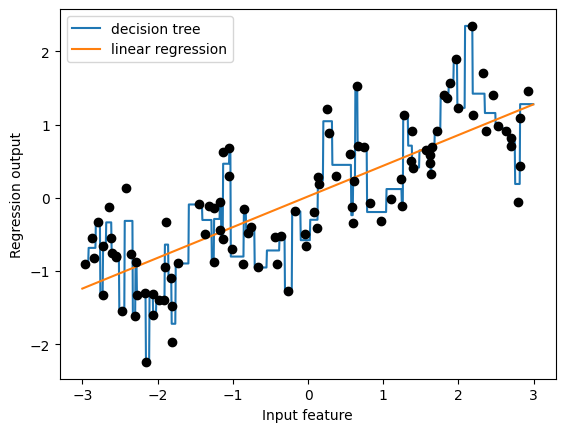

In [11]:
# ===== 书 4.2 节：wave 数据集上线性回归 vs 决策树回归 =====
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

X, y = mglearn.datasets.make_wave(n_samples=100)
line = np.linspace(-3, 3, 1000, endpoint=False).reshape(-1, 1)  # 画预测曲线用的密集网格

reg = DecisionTreeRegressor(min_samples_split=3).fit(X, y)
plt.plot(line, reg.predict(line), label="decision tree")

reg = LinearRegression().fit(X, y)
plt.plot(line, reg.predict(line), label="linear regression")

plt.plot(X[:, 0], y, 'o', c='k')
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")

In [12]:
# ===== 书 4.2 节：定义 10 个均匀箱子 =====
bins = np.linspace(-3, 3, 11)
print("bins: {}".format(bins))

bins: [-3.  -2.4 -1.8 -1.2 -0.6  0.   0.6  1.2  1.8  2.4  3. ]


In [13]:
# ===== 书 4.2 节：记录每个数据点所属的箱子 =====
which_bin = np.digitize(X, bins=bins)
print("\nData points:\n", X[:5])
print("\nBin membership for data points:\n", which_bin[:5])


Data points:
 [[-0.75275929]
 [ 2.70428584]
 [ 1.39196365]
 [ 0.59195091]
 [-2.06388816]]

Bin membership for data points:
 [[ 4]
 [10]
 [ 8]
 [ 6]
 [ 2]]


In [14]:
# ===== 书 4.2 节：箱子编号 → one-hot 编码 =====
from sklearn.preprocessing import OneHotEncoder
# 使用 OneHotEncoder 进行变换
encoder = OneHotEncoder(sparse_output=False)  # 版本适配：原书 sparse=False，sklearn 1.2 起改名 sparse_output
# encoder.fit 找到 which_bin 中的唯一值
encoder.fit(which_bin)
# transform 创建 one-hot 编码
X_binned = encoder.transform(which_bin)
print(X_binned[:5])
print("X_binned.shape: {}".format(X_binned.shape))

[[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]
X_binned.shape: (100, 10)


Text(0.5, 0, 'Input feature')

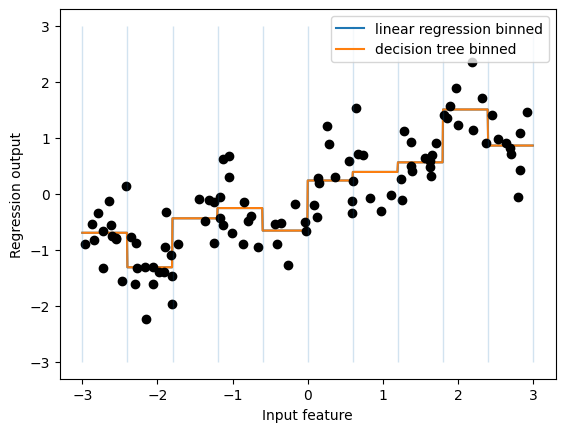

In [15]:
# ===== 书 4.2 节：在分箱特征上重建两个模型 =====
line_binned = encoder.transform(np.digitize(line, bins=bins))  # 对网格线也做同样的分箱+编码

reg = LinearRegression().fit(X_binned, y)
plt.plot(line, reg.predict(line_binned), label='linear regression binned')

reg = DecisionTreeRegressor(min_samples_split=3).fit(X_binned, y)
plt.plot(line, reg.predict(line_binned), label='decision tree binned')
plt.plot(X[:, 0], y, 'o', c='k')
plt.vlines(bins, -3, 3, linewidth=1, alpha=.2)  # 黑色虚线 = 箱子边界
plt.legend(loc="best")
plt.ylabel("Regression output")
plt.xlabel("Input feature")

## 4.3 交互特征与多项式特征

想要丰富特征表示（特别是对于线性模型而言），另一种方法是添加原始数据的**交互特征（interaction feature）**和**多项式特征（polynomial feature）**。这种特征工程通常用于统计建模，但也常用于许多实际的机器学习应用中。

In [16]:
# ===== 书 4.3 节：分箱特征 + 原始特征（单一全局斜率） =====
X_combined = np.hstack([X, X_binned])   # 1 个原始特征 + 10 个箱子指示特征
print(X_combined.shape)

(100, 11)


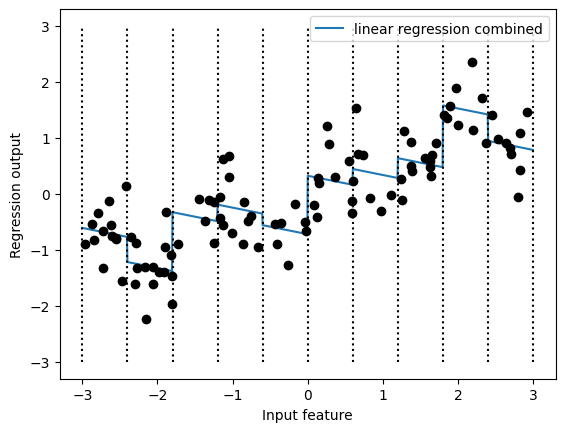

In [17]:
# ===== 书 4.3 节：训练并可视化 =====
reg = LinearRegression().fit(X_combined, y)

line_combined = np.hstack([line, line_binned])
plt.plot(line, reg.predict(line_combined), label='linear regression combined')

for bin in bins:
    plt.plot([bin, bin], [-3, 3], ':', c='k')  # 点线标出箱子边界

plt.legend(loc="best")
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.plot(X[:, 0], y, 'o', c='k')

In [18]:
# ===== 书 4.3 节：交互特征（每箱一个斜率） =====
X_product = np.hstack([X_binned, X * X_binned])   # 10 个箱子指示 + 10 个"箱内才生效"的 x 值
print(X_product.shape)

(100, 20)


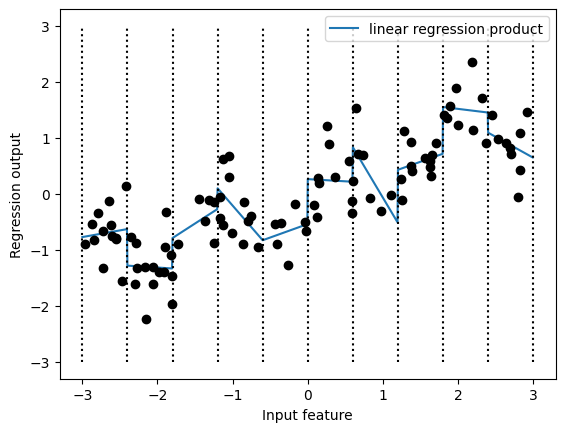

In [19]:
# ===== 书 4.3 节：交互特征上的线性回归 =====
reg = LinearRegression().fit(X_product, y)

line_product = np.hstack([line_binned, line * line_binned])
plt.plot(line, reg.predict(line_product), label='linear regression product')

for bin in bins:
    plt.plot([bin, bin], [-3, 3], ':', c='k')

plt.plot(X[:, 0], y, 'o', c='k')
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")

### 使用原始特征的多项式

使用分箱是扩展连续特征的一种方法。另一种方法是使用原始特征的**多项式（polynomial）**：对于给定特征 \(x\)，可以考虑 \(x^2\)、\(x^3\)、\(x^4\) 等等。这在 preprocessing 模块的 `PolynomialFeatures` 中实现：

In [20]:
# ===== 书 4.3 节：PolynomialFeatures 生成 10 次多项式特征 =====
from sklearn.preprocessing import PolynomialFeatures

# 包含直到 x ** 10 的多项式:
# 默认的 "include_bias=True" 会添加恒等于 1 的常数特征
poly = PolynomialFeatures(degree=10, include_bias=False)
poly.fit(X)
X_poly = poly.transform(X)
print("X_poly.shape: {}".format(X_poly.shape))

X_poly.shape: (100, 10)


In [21]:
# ===== 书 4.3 节：对比原始特征与多项式特征 =====
print("Entries of X:\n{}".format(X[:5]))
print("Entries of X_poly:\n{}".format(X_poly[:5]))

Entries of X:
[[-0.75275929]
 [ 2.70428584]
 [ 1.39196365]
 [ 0.59195091]
 [-2.06388816]]
Entries of X_poly:
[[-7.52759287e-01  5.66646544e-01 -4.26548448e-01  3.21088306e-01
  -2.41702204e-01  1.81943579e-01 -1.36959719e-01  1.03097700e-01
  -7.76077513e-02  5.84199555e-02]
 [ 2.70428584e+00  7.31316190e+00  1.97768801e+01  5.34823369e+01
   1.44631526e+02  3.91124988e+02  1.05771377e+03  2.86036036e+03
   7.73523202e+03  2.09182784e+04]
 [ 1.39196365e+00  1.93756281e+00  2.69701700e+00  3.75414962e+00
   5.22563982e+00  7.27390068e+00  1.01250053e+01  1.40936394e+01
   1.96178338e+01  2.73073115e+01]
 [ 5.91950905e-01  3.50405874e-01  2.07423074e-01  1.22784277e-01
   7.26822637e-02  4.30243318e-02  2.54682921e-02  1.50759786e-02
   8.92423917e-03  5.28271146e-03]
 [-2.06388816e+00  4.25963433e+00 -8.79140884e+00  1.81444846e+01
  -3.74481869e+01  7.72888694e+01 -1.59515582e+02  3.29222321e+02
  -6.79478050e+02  1.40236670e+03]]


In [22]:
# ===== 书 4.3 节：多项式特征的名字 =====
print("Polynomial feature names:\n{}".format(poly.get_feature_names_out()))  # 版本适配：原书 get_feature_names，sklearn 1.0 起改名 get_feature_names_out

Polynomial feature names:
['x0' 'x0^2' 'x0^3' 'x0^4' 'x0^5' 'x0^6' 'x0^7' 'x0^8' 'x0^9' 'x0^10']


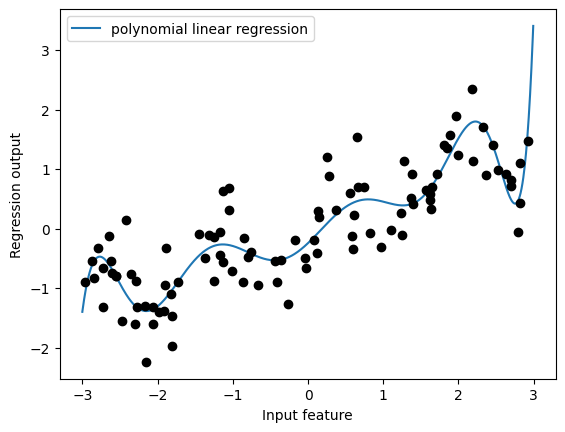

In [23]:
# ===== 书 4.3 节：10 次多项式回归 =====
reg = LinearRegression().fit(X_poly, y)

line_poly = poly.transform(line)
plt.plot(line, reg.predict(line_poly), label='polynomial linear regression')
plt.plot(X[:, 0], y, 'o', c='k')
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")

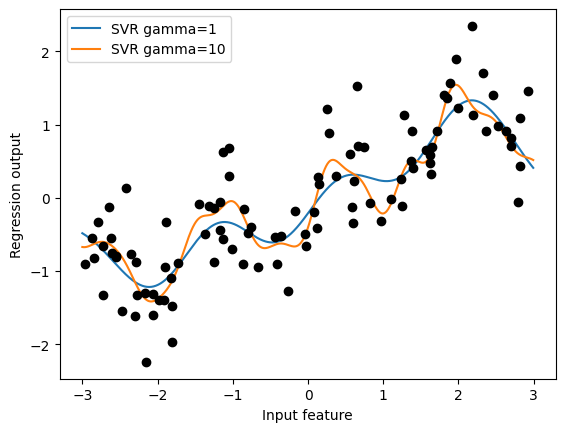

In [24]:
# ===== 书 4.3 节：核 SVM 无需显式特征变换 =====
from sklearn.svm import SVR

for gamma in [1, 10]:
    svr = SVR(gamma=gamma).fit(X, y)
    plt.plot(line, svr.predict(line), label='SVR gamma={}'.format(gamma))

plt.plot(X[:, 0], y, 'o', c='k')
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")

### 更实际的应用：波士顿房价数据集

作为对交互特征和多项式特征更加实际的应用，我们再次观察**波士顿房价数据集**（第 2 章已在这个数据集上使用过多项式特征）。现在来看一下这些特征的构造方式，以及多项式特征的帮助有多大。首先加载数据，然后利用 MinMaxScaler 将其缩放到 0 和 1 之间：

In [25]:
# ===== 书 4.3 节：加载波士顿房价并缩放 =====
from mglearn.datasets import load_boston  # 版本适配：sklearn≥1.2 移除 load_boston，改用 mglearn 内置等价加载（本地缓存）
# 版本适配：mglearn 内置等价加载（boston.data/target 用法不变，本地缓存离线可跑）
from mglearn.datasets import load_boston
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

boston = load_boston()
X_train, X_test, y_train, y_test = train_test_split(
    boston.data, boston.target, random_state=0)

# 缩放数据
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
# ===== 书 4.3 节：degree=2 的多项式与交互特征 =====
poly = PolynomialFeatures(degree=2).fit(X_train_scaled)
X_train_poly = poly.transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)
print("X_train.shape: {}".format(X_train.shape))
print("X_train_poly.shape: {}".format(X_train_poly.shape))

X_train.shape: (379, 13)
X_train_poly.shape: (379, 105)


In [27]:
# ===== 书 4.3 节：105 个特征的名字 =====
print("Polynomial feature names:\n{}".format(poly.get_feature_names_out()))  # 版本适配：原书 get_feature_names，sklearn 1.0 起改名 get_feature_names_out

Polynomial feature names:
['1' 'x0' 'x1' 'x2' 'x3' 'x4' 'x5' 'x6' 'x7' 'x8' 'x9' 'x10' 'x11' 'x12'
 'x0^2' 'x0 x1' 'x0 x2' 'x0 x3' 'x0 x4' 'x0 x5' 'x0 x6' 'x0 x7' 'x0 x8'
 'x0 x9' 'x0 x10' 'x0 x11' 'x0 x12' 'x1^2' 'x1 x2' 'x1 x3' 'x1 x4' 'x1 x5'
 'x1 x6' 'x1 x7' 'x1 x8' 'x1 x9' 'x1 x10' 'x1 x11' 'x1 x12' 'x2^2' 'x2 x3'
 'x2 x4' 'x2 x5' 'x2 x6' 'x2 x7' 'x2 x8' 'x2 x9' 'x2 x10' 'x2 x11'
 'x2 x12' 'x3^2' 'x3 x4' 'x3 x5' 'x3 x6' 'x3 x7' 'x3 x8' 'x3 x9' 'x3 x10'
 'x3 x11' 'x3 x12' 'x4^2' 'x4 x5' 'x4 x6' 'x4 x7' 'x4 x8' 'x4 x9' 'x4 x10'
 'x4 x11' 'x4 x12' 'x5^2' 'x5 x6' 'x5 x7' 'x5 x8' 'x5 x9' 'x5 x10'
 'x5 x11' 'x5 x12' 'x6^2' 'x6 x7' 'x6 x8' 'x6 x9' 'x6 x10' 'x6 x11'
 'x6 x12' 'x7^2' 'x7 x8' 'x7 x9' 'x7 x10' 'x7 x11' 'x7 x12' 'x8^2' 'x8 x9'
 'x8 x10' 'x8 x11' 'x8 x12' 'x9^2' 'x9 x10' 'x9 x11' 'x9 x12' 'x10^2'
 'x10 x11' 'x10 x12' 'x11^2' 'x11 x12' 'x12^2']


In [28]:
# ===== 书 4.3 节：Ridge 对比 =====
from sklearn.linear_model import Ridge
ridge = Ridge().fit(X_train_scaled, y_train)
print("Score without interactions: {:.3f}".format(
    ridge.score(X_test_scaled, y_test)))
ridge = Ridge().fit(X_train_poly, y_train)
print("Score with interactions: {:.3f}".format(
    ridge.score(X_test_poly, y_test)))

Score without interactions: 0.621
Score with interactions: 0.753


In [29]:
# ===== 书 4.3 节：随机森林对比 =====
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100).fit(X_train_scaled, y_train)
print("Score without interactions: {:.3f}".format(
    rf.score(X_test_scaled, y_test)))
rf = RandomForestRegressor(n_estimators=100).fit(X_train_poly, y_train)
print("Score with interactions: {:.3f}".format(rf.score(X_test_poly, y_test)))

Score without interactions: 0.788


Score with interactions: 0.768


## 4.4 单变量非线性变换

上一节看到，添加特征的平方或立方可以改进线性回归模型。**其他数学函数的变换通常也有用，特别是 log、exp 或 sin**。虽然基于树的模型只关注特征的**顺序**，但线性模型和神经网络依赖于每个特征的**尺度和分布**。如果在特征和目标之间存在非线性关系，那么建模就变得非常困难，特别是对于回归问题。log 和 exp 函数可以帮助**调节数据的相对比例**，从而改进线性模型或神经网络的学习效果（第 2 章对内存价格数据应用过这种函数）。在处理具有**周期性模式**的数据时，sin 和 cos 函数非常有用。

In [30]:
# ===== 书 4.4 节：构造模拟计数数据 =====
rnd = np.random.RandomState(0)
X_org = rnd.normal(size=(1000, 3))   # 原始高斯噪声
w = rnd.normal(size=3)               # 随机权重

X = rnd.poisson(10 * np.exp(X_org))  # 泊松计数：强度 = 10 * exp(高斯) → 右偏长尾
y = np.dot(X_org, w)                 # 目标由高斯底层的 X_org 线性决定

In [31]:
# ===== 书 4.4 节：统计取值出现次数 =====
print("Number of feature appearances:\n{}".format(np.bincount(X[:, 0])))

Number of feature appearances:
[28 38 68 48 61 59 45 56 37 40 35 34 36 26 23 26 27 21 23 23 18 21 10  9
 17  9  7 14 12  7  3  8  4  5  5  3  4  2  4  1  1  3  2  5  3  8  2  5
  2  1  2  3  3  2  2  3  3  0  1  2  1  0  0  3  1  0  0  0  1  3  0  1
  0  2  0  1  1  0  0  0  0  1  0  0  2  2  0  1  1  0  0  0  0  1  1  0
  0  0  0  0  0  0  1  0  0  0  0  0  1  1  0  0  1  0  0  0  0  0  0  0
  1  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1]


Text(0.5, 0, 'Value')

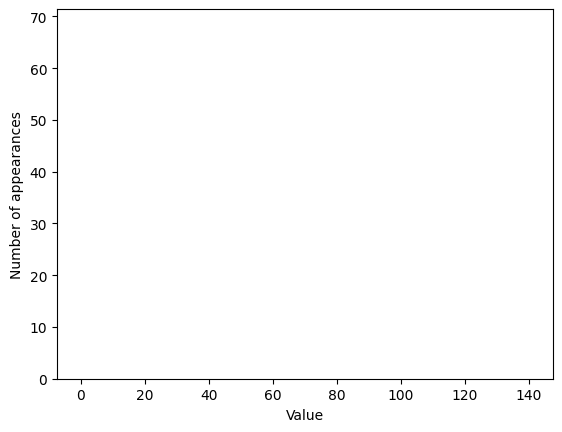

In [32]:
# ===== 书 4.4 节：计数特征直方图 =====
bins = np.bincount(X[:, 0])
plt.bar(range(len(bins)), bins, color='w')
plt.ylabel("Number of appearances")
plt.xlabel("Value")

In [33]:
# ===== 书 4.4 节：未变换的 Ridge =====
from sklearn.linear_model import Ridge
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
score = Ridge().fit(X_train, y_train).score(X_test, y_test)
print("Test score: {:.3f}".format(score))

Test score: 0.622


In [34]:
# ===== 书 4.4 节：log(X + 1) 变换 =====
X_train_log = np.log(X_train + 1)
X_test_log = np.log(X_test + 1)

Text(0.5, 0, 'Value')

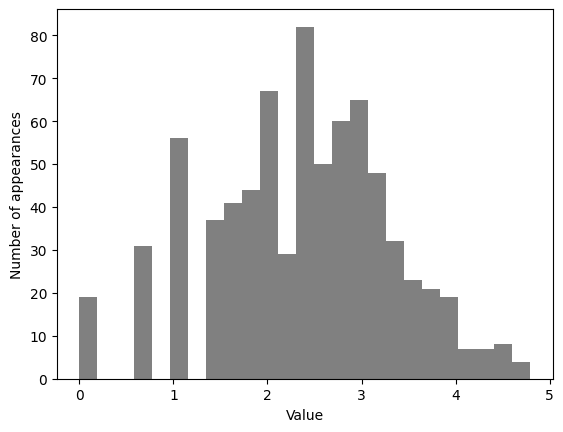

In [35]:
# ===== 书 4.4 节：变换后的直方图 =====
plt.hist(X_train_log[:, 0], bins=25, color='gray')
plt.ylabel("Number of appearances")
plt.xlabel("Value")

In [36]:
# ===== 书 4.4 节：log 变换后的 Ridge =====
score = Ridge().fit(X_train_log, y_train).score(X_test_log, y_test)
print("Test score: {:.3f}".format(score))

Test score: 0.875


## 4.5 自动化特征选择

有了这么多种创建新特征的方法，你可能会想要增大数据的维度，使其远大于原始特征的数量。但是，**添加更多特征会使所有模型变得更加复杂，从而增大过拟合的可能性**。在添加新特征或处理一般的高维数据集时，最好将特征的数量减少到**只包含最有用的那些特征**，并删除其余特征——这样会得到泛化能力更好、更简单的模型。

### 4.5.1 单变量统计

在单变量统计中，我们计算**每个特征和目标值之间的关系是否存在统计显著性**，然后选择具有最高置信度的特征。对于分类问题，这也被称为**方差分析（analysis of variance，ANOVA）**。这些测试的一个关键性质是它们是**单变量的（univariate）**，即**只单独考虑每个特征**：如果一个特征只有在与另一个特征合并时才具有信息量，那么这个特征将被舍弃。单变量测试的计算速度通常很快，并且**不需要构建模型**；另一方面，它们完全独立于你之后想要应用的模型。

In [37]:
# ===== 书 4.5.1 节：cancer 数据 + 50 列纯噪声 =====
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectPercentile
from sklearn.model_selection import train_test_split

cancer = load_breast_cancer()

# 获得确定性的随机数
rng = np.random.RandomState(42)
noise = rng.normal(size=(len(cancer.data), 50))
# 向数据中添加噪声特征
# 前 30 个特征来自数据集，后 50 个是噪声
X_w_noise = np.hstack([cancer.data, noise])

X_train, X_test, y_train, y_test = train_test_split(
    X_w_noise, cancer.target, random_state=0, test_size=.5)
# 使用 f_classif（默认值）和 SelectPercentile 来选择 50% 的特征
select = SelectPercentile(percentile=50)
select.fit(X_train, y_train)
# 对训练集进行变换
X_train_selected = select.transform(X_train)

print("X_train.shape: {}".format(X_train.shape))
print("X_train_selected.shape: {}".format(X_train_selected.shape))

X_train.shape: (284, 80)


X_train_selected.shape: (284, 40)


[ True  True  True  True  True  True  True  True  True False  True False
  True  True  True  True  True  True False False  True  True  True  True
  True  True  True  True  True  True False False False  True False  True
 False False  True False False False False  True False False  True False
 False  True False  True False False False False False False  True False
  True False False False False  True False  True False False False False
  True  True False  True False False False False]


Text(0.5, 0, 'Sample index')

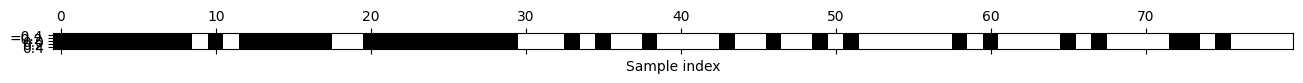

In [38]:
# ===== 书 4.5.1 节：查看特征遮罩 =====
mask = select.get_support()
print(mask)
# 将遮罩可视化——黑色为 True，白色为 False
plt.matshow(mask.reshape(1, -1), cmap='gray_r')
plt.xlabel("Sample index")

In [39]:
# ===== 书 4.5.1 节：特征选择前后的 LogisticRegression =====
from sklearn.linear_model import LogisticRegression

# 对测试数据进行变换
X_test_selected = select.transform(X_test)

lr = LogisticRegression()
lr.fit(X_train, y_train)
print("Score with all features: {:.3f}".format(lr.score(X_test, y_test)))
lr.fit(X_train_selected, y_train)
print("Score with only selected features: {:.3f}".format(
    lr.score(X_test_selected, y_test)))

Score with all features: 0.919
Score with only selected features: 0.916


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

### 4.5.2 基于模型的特征选择

**基于模型的特征选择**使用一个监督机器学习模型来判断每个特征的重要性，并且仅保留最重要的特征。注意：**用于特征选择的监督模型不需要与用于最终监督建模的模型相同**。特征选择模型需要为每个特征提供某种**重要性度量**，以便用这个度量对特征进行排序。决策树和基于决策树的模型提供了 `feature_importances_` 属性，直接编码每个特征的重要性；**线性模型系数的绝对值**也可以用于表示特征重要性。第 2 章见过，**L1 惩罚的线性模型学到的是稀疏系数**，只用到特征的一个很小的子集——这可以被视为模型本身的一种特征选择形式，但也可以用作另一个模型选择特征的预处理步骤。

In [40]:
# ===== 书 4.5.2 节：SelectFromModel + 随机森林 =====
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
select = SelectFromModel(
    RandomForestClassifier(n_estimators=100, random_state=42),
    threshold="median")

In [41]:
# ===== 书 4.5.2 节：拟合并变换 =====
select.fit(X_train, y_train)
X_train_l1 = select.transform(X_train)
print("X_train.shape: {}".format(X_train.shape))
print("X_train_l1.shape: {}".format(X_train_l1.shape))

X_train.shape: (284, 80)
X_train_l1.shape: (284, 40)


Text(0.5, 0, 'Sample index')

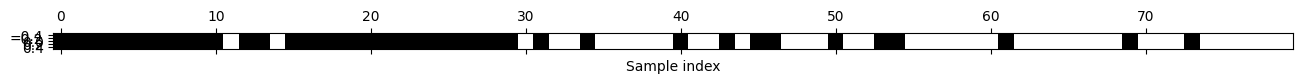

In [42]:
# ===== 书 4.5.2 节：遮罩可视化 =====
mask = select.get_support()
# 将遮罩可视化——黑色为 True，白色为 False
plt.matshow(mask.reshape(1, -1), cmap='gray_r')
plt.xlabel("Sample index")

In [43]:
# ===== 书 4.5.2 节：选择后训练 LogisticRegression =====
X_test_l1 = select.transform(X_test)
score = LogisticRegression().fit(X_train_l1, y_train).score(X_test_l1, y_test)
print("Test score: {:.3f}".format(score))

Test score: 0.940


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 4.5.3 迭代特征选择

在单变量测试中，我们没有使用模型；在基于模型的选择中，我们使用了单个模型来选择特征。**迭代特征选择**则会构建**一系列模型，每个模型都使用不同数量的特征**。有两种基本方法：

Text(0.5, 0, 'Sample index')

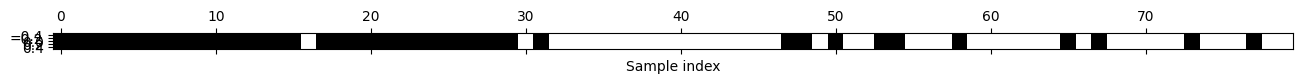

In [44]:
# ===== 书 4.5.3 节：RFE 递归特征消除 =====
from sklearn.feature_selection import RFE
select = RFE(RandomForestClassifier(n_estimators=100, random_state=42),
             n_features_to_select=40)
select.fit(X_train, y_train)
# 将选中的特征可视化：
mask = select.get_support()
plt.matshow(mask.reshape(1, -1), cmap='gray_r')
plt.xlabel("Sample index")

In [45]:
# ===== 书 4.5.3 节：RFE 之后的 LogisticRegression =====
X_train_rfe = select.transform(X_train)
X_test_rfe = select.transform(X_test)

score = LogisticRegression().fit(X_train_rfe, y_train).score(X_test_rfe, y_test)
print("Test score: {:.3f}".format(score))

Test score: 0.930


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [46]:
# ===== 书 4.5.3 节：RFE 内部模型直接预测 =====
print("Test score: {:.3f}".format(select.score(X_test, y_test)))

Test score: 0.951


## 4.6 利用专家知识

对于特定应用来说，在特征工程中通常可以利用**专家知识（expert knowledge）**。虽然在许多情况下，机器学习的目的是**避免**创建一组专家设计的规则，但这并不意味着应该舍弃该应用或该领域的先验知识。通常来说，领域专家可以帮助找出有用的特征，其信息量比数据原始表示要大得多。

In [47]:
# ===== 书 4.6 节：加载 Citi Bike 数据 =====
citibike = mglearn.datasets.load_citibike()
print("Citi Bike data:\n{}".format(citibike.head()))

Citi Bike data:
starttime
2015-08-01 00:00:00     3
2015-08-01 03:00:00     0
2015-08-01 06:00:00     9
2015-08-01 09:00:00    41
2015-08-01 12:00:00    39
Freq: 3h, Name: one, dtype: int64


Text(0, 0.5, 'Rentals')

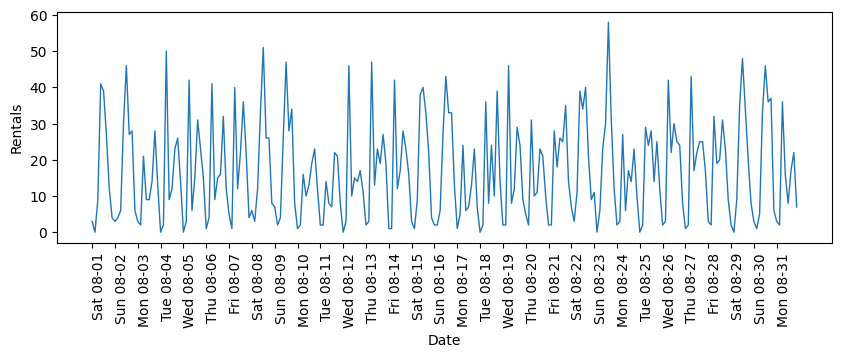

In [48]:
# ===== 书 4.6 节：整月租车数量曲线 =====
plt.figure(figsize=(10, 3))
xticks = pd.date_range(start=citibike.index.min(), end=citibike.index.max(),
                       freq='D')  # 每天一个刻度
plt.xticks(xticks, xticks.strftime("%a %m-%d"), rotation=90, ha="left")
plt.plot(citibike, linewidth=1)
plt.xlabel("Date")
plt.ylabel("Rentals")

In [49]:
# ===== 书 4.6 节：目标值 + POSIX 时间特征 =====
# 提取目标值（租车数量）
y = citibike.values
# 利用 "%s" 将时间转换为 POSIX 时间
X = ((citibike.index - pd.Timestamp("1970-01-01")) // pd.Timedelta("1s")).to_numpy().reshape(-1, 1)  # 版本适配：strftime("%s") Windows 不可用，pandas 2.x 等价写法
# 版本适配：等价取 POSIX 秒
X = ((citibike.index - pd.Timestamp("1970-01-01")) // pd.Timedelta("1s")).to_numpy().reshape(-1, 1)

In [50]:
# ===== 书 4.6 节：评估函数 eval_on_features =====
# 使用前 184 个数据点用于训练，剩余的数据点用于测试
n_train = 184

# 对给定特征集上的回归进行评估和作图的函数
def eval_on_features(features, target, regressor):
    # 将给定特征划分为训练集和测试集
    X_train, X_test = features[:n_train], features[n_train:]
    # 同样划分目标数组
    y_train, y_test = target[:n_train], target[n_train:]
    regressor.fit(X_train, y_train)
    print("Test-set R^2: {:.2f}".format(regressor.score(X_test, y_test)))
    y_pred = regressor.predict(X_test)
    y_pred_train = regressor.predict(X_train)
    plt.figure(figsize=(10, 3))
    plt.xticks(range(0, len(X), 8), xticks.strftime("%a %m-%d"), rotation=90,
               ha="left")
    plt.plot(range(n_train), y_train, label="train")
    plt.plot(range(n_train, len(y_test) + n_train), y_test, '-', label="test")
    plt.plot(range(n_train), y_pred_train, '--', label="prediction train")
    plt.plot(range(n_train, len(y_test) + n_train), y_pred, '--',
             label="prediction test")
    plt.legend(loc=(1.01, 0))
    plt.xlabel("Date")
    plt.ylabel("Rentals")

Test-set R^2: -0.04


<Figure size 640x480 with 0 Axes>

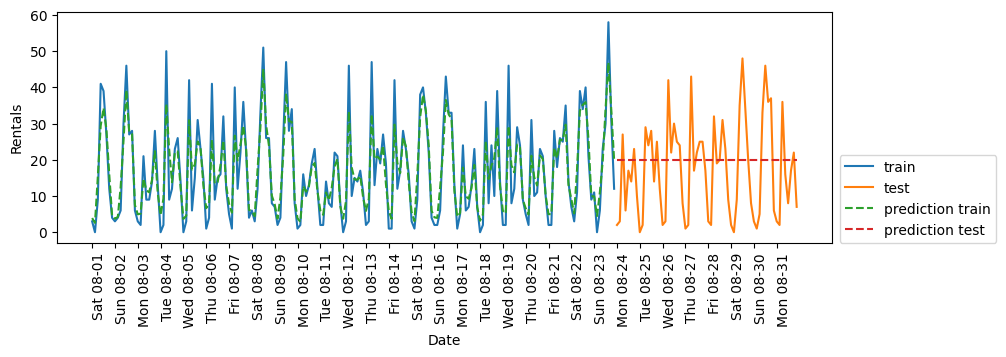

In [51]:
# ===== 书 4.6 节：随机森林 + POSIX 时间 =====
from sklearn.ensemble import RandomForestRegressor
regressor = RandomForestRegressor(n_estimators=100, random_state=0)
plt.figure()
eval_on_features(X, y, regressor)

Test-set R^2: 0.60


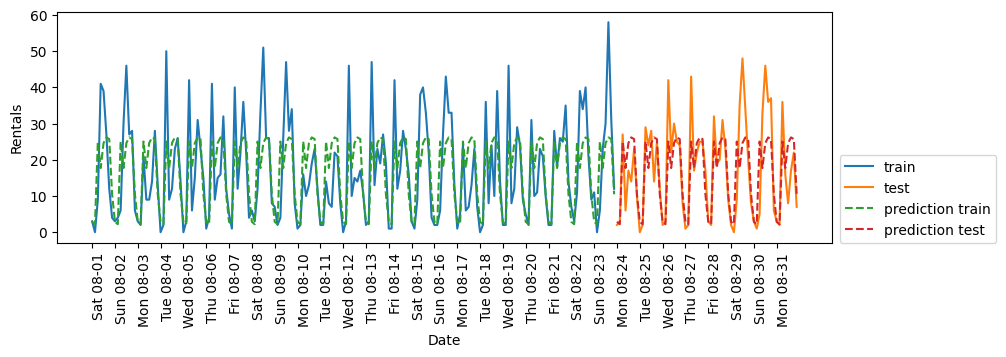

In [52]:
# ===== 书 4.6 节：特征 1 —— 每天的时刻 =====
X_hour = citibike.index.hour.values.reshape(-1, 1)  # 原书写法 .reshape()，新 pandas 需 .values.reshape
eval_on_features(X_hour, y, regressor)

Test-set R^2: 0.84


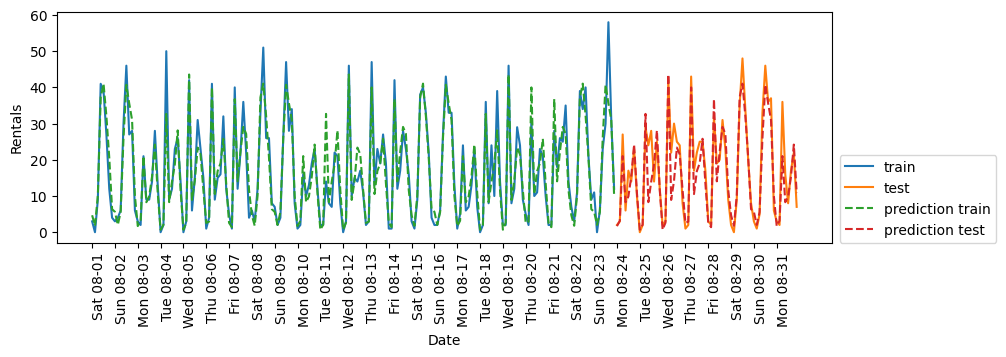

In [53]:
# ===== 书 4.6 节：特征 2 —— 加上一周的星期几 =====
X_hour_week = np.hstack([citibike.index.dayofweek.values.reshape(-1, 1),
                         citibike.index.hour.values.reshape(-1, 1)])
eval_on_features(X_hour_week, y, regressor)

Test-set R^2: 0.13


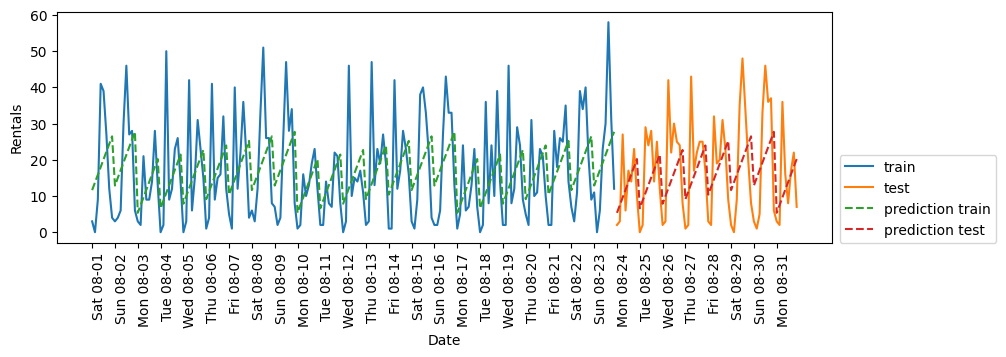

In [54]:
# ===== 书 4.6 节：线性模型 + 整数连续编码（失败案例） =====
from sklearn.linear_model import LinearRegression
eval_on_features(X_hour_week, y, LinearRegression())

Test-set R^2: 0.62


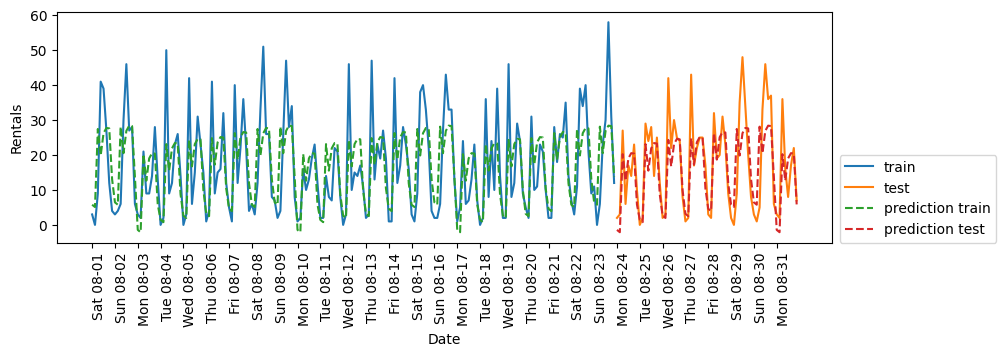

In [55]:
# ===== 书 4.6 节：one-hot 编码后重试线性模型 =====
enc = OneHotEncoder()
X_hour_week_onehot = enc.fit_transform(X_hour_week).toarray()  # 稀疏矩阵 → 密集数组
eval_on_features(X_hour_week_onehot, y, Ridge())

Test-set R^2: 0.85


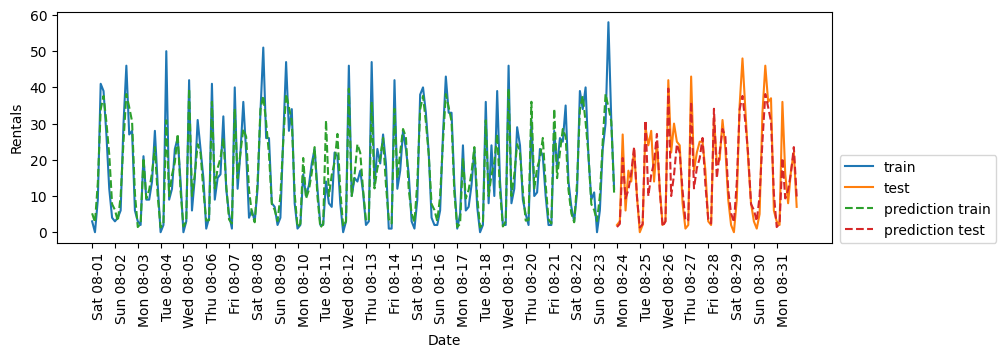

In [56]:
# ===== 书 4.6 节：交互特征——每种组合一个系数 =====
poly_transformer = PolynomialFeatures(degree=2, interaction_only=True,
                                      include_bias=False)
X_hour_week_onehot_poly = poly_transformer.fit_transform(X_hour_week_onehot)
lr = Ridge()
eval_on_features(X_hour_week_onehot_poly, y, lr)

In [57]:
# ===== 书 4.6 节：为特征起名字 =====
hour = ["%02d:00" % i for i in range(0, 24, 3)]   # 00:00, 03:00, ..., 21:00
day = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
features = day + hour

In [58]:
# ===== 书 4.6 节：给交互特征命名并筛出非零系数 =====
features_poly = poly_transformer.get_feature_names_out(features)  # 版本适配：原书 get_feature_names，sklearn 1.0 起改名 get_feature_names_out
features_nonzero = np.array(features_poly)[lr.coef_ != 0]
coef_nonzero = lr.coef_[lr.coef_ != 0]

Text(0, 0.5, 'Feature magnitude')

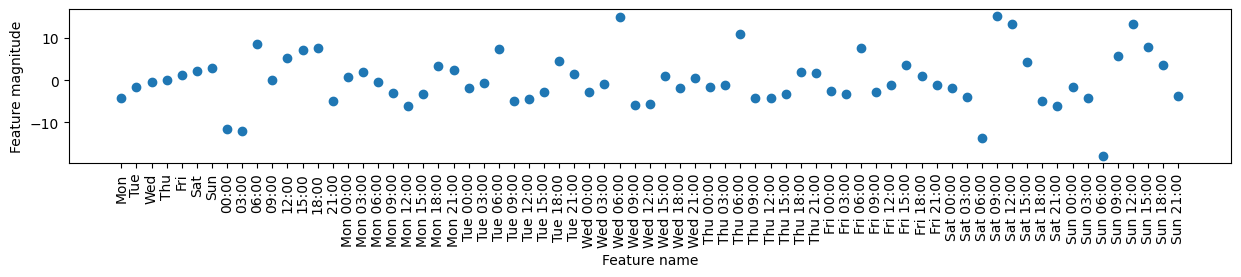

In [59]:
# ===== 书 4.6 节：可视化学到的系数 =====
plt.figure(figsize=(15, 2))
plt.plot(coef_nonzero, 'o')
plt.xticks(np.arange(len(coef_nonzero)), features_nonzero, rotation=90)
plt.xlabel("Feature name")
plt.ylabel("Feature magnitude")

## 4.7 小结与展望

本章讨论了如何处理不同的数据类型（特别是分类变量）。我们强调了**使用适合机器学习算法的数据表示方式的重要性**，例如 one-hot 编码过的分类变量。还讨论了通过特征工程生成新特征的重要性，以及**利用专家知识从数据中创建导出特征**的可能性。特别是**线性模型**，可能会从分箱、添加多项式和交互项而生成的新特征中大大受益；对于更加复杂的非线性模型（比如随机森林和 SVM），在无需显式扩展特征空间的前提下就可以学习更加复杂的任务。在实践中，**所使用的特征（以及特征与方法之间的匹配）通常是使机器学习方法表现良好的最重要的因素**。